In [15]:
import pandas as pd
import matplotlib.pyplot as plt

#Data Loading

In [16]:
df = pd.read_csv("telco_churn.csv")
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


#First look (types, duplicates, class balance)

In [17]:
df.info()
print("Duplicate rows:", df.duplicated().sum())
print(df["Churn"].value_counts(normalize=True).round(3))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


- The dataset has 7,043 customers and 21 columns.
- Most columns are text (object), and tenure and SeniorCitizen are integers. MonthlyCharges is a decimal number.
- TotalCharges is stored as text even though it holds numbers. I need to convert it before modeling, because models can only use numeric values.
- Checking for duplicates returned 0, so no rows need removing.
- The churn rate is about 26.5%, so the data is imbalanced. Most customers stay, so a model could score well by predicting "stay" every time. That's why I'll focus on recall.

#Data Cleaning

In [18]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())

df = df.dropna(subset=["TotalCharges"]).drop(columns="customerID")
df["Churn"] = (df["Churn"] == "Yes").astype(int)   # 1 = left, 0 = stayed
print(df.shape)

Missing TotalCharges: 11
(7032, 20)


TotalCharges should hold numbers, but pandas stored it as text because 11 rows contain a blank space. Models do arithmetic on their inputs (scaling, distances, splitting), and they can't do that with text. So I convert the column with errors="coerce", which turns the blanks into missing values (NaN) that I can count.

*Why I dropped the rows instead of filling them:*
- Those 11 customers have tenure 0, so they're brand-new and haven't been billed yet. Filling in a number, such as 0 or the median, would invent a billing history that doesn't exist.
- 11 rows out of 7,043 is about 0.16%, so dropping them barely changes the data.
- Dropping keeps the data honest. If I had many missing values, I would use an imputer instead, and I would explain that choice.

#Exploratory Data Analysis (EDA)

Before modeling, I want to know why customers leave. The model predicts who will churn, but the business needs to know what drives churn so it can act on it.

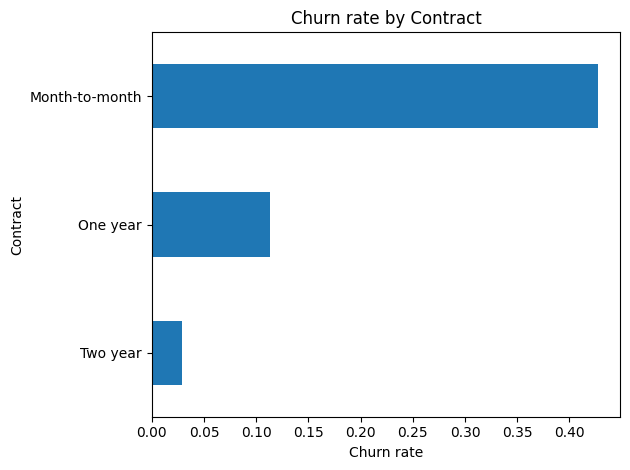

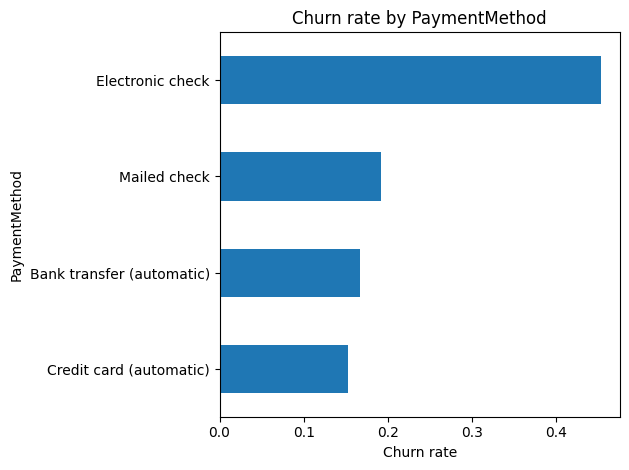

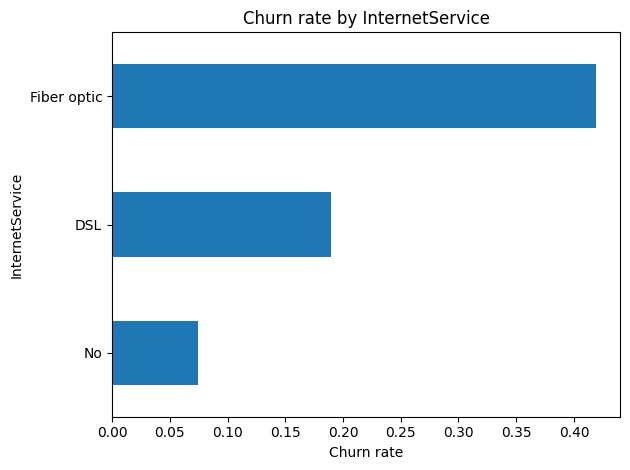

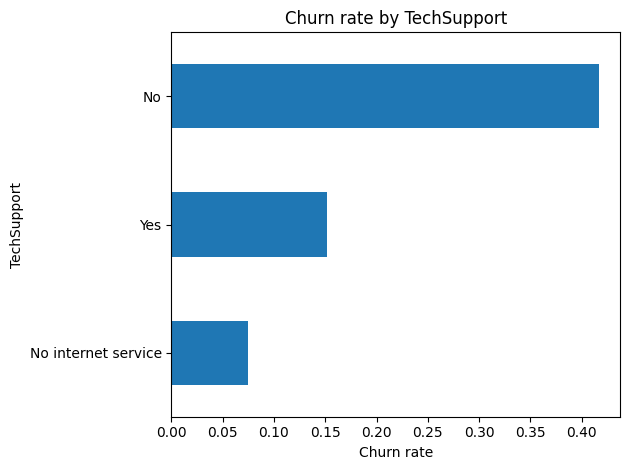

In [19]:
for col in ["Contract", "PaymentMethod", "InternetService", "TechSupport"]:
    rates = df.groupby(col)["Churn"].mean().sort_values()
    rates.plot(kind="barh", title=f"Churn rate by {col}")
    plt.xlabel("Churn rate")
    plt.tight_layout()
    plt.show()

Churn rate by contract type:
- Month-to-month: about 43%
- One year: about 11%
- Two year: about 3%

Customers on month-to-month contracts leave far more often than customers on longer contracts. The chart shows the rate falling sharply as the contract gets longer. This suggests that a longer commitment keeps customers, so a contract-upgrade offer is a good retention action.

Churn rate by payment method, internet service and tech support:
- Electronic check has the highest churn (about 45%).
- The three other payment methods are between about 15% and 19%.
- Fiber optic customers churn at about 42%, which is much higher than DSL (about 19%) or no internet (about 7%).
- Customers without tech support churn at about 42%, compared with about 15% for those who have it.

Several of these groups overlap. For example, many fiber optic customers may also be on month-to-month contracts, so I can't yet say which factor matters most. The model will help separate them.

Tech support looks like a retention lever. Offering a free trial could help keep customers who are at risk.

In [20]:
pd.crosstab(df["InternetService"], df["Contract"])

Contract,Month-to-month,One year,Two year
InternetService,,,
DSL,1223,570,623
Fiber optic,2128,539,429
No,524,363,633


I used this to check the overlap claim before i keep it.

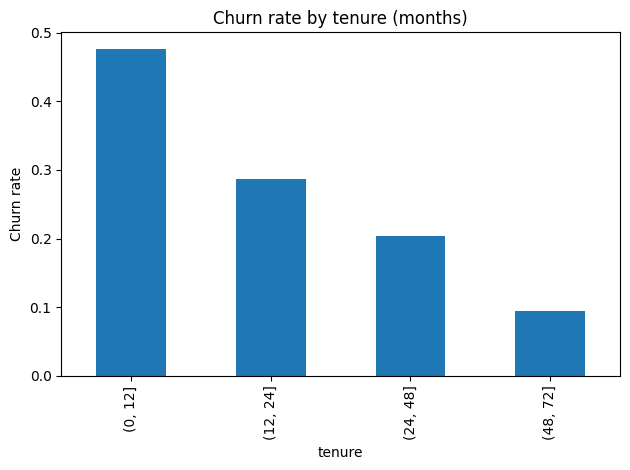

In [21]:
tenure_rates = df.groupby(pd.cut(df["tenure"], bins=[0, 12, 24, 48, 72]), observed=True)["Churn"].mean()
tenure_rates.plot(kind="bar", title="Churn rate by tenure (months)")
plt.ylabel("Churn rate")
plt.tight_layout()
plt.show()

Churn rate by tenure:
- Months 1–12: about 48%
- Months 13–24: about 29%
- Months 25–48: about 20%
- Months 49–72: about 9%

Churn is highest in the first year and drops with each band. Customers who stay past two years are much less likely to leave. This points to the first year as the most important time for retention, such as onboarding check-ins or early contract offers.

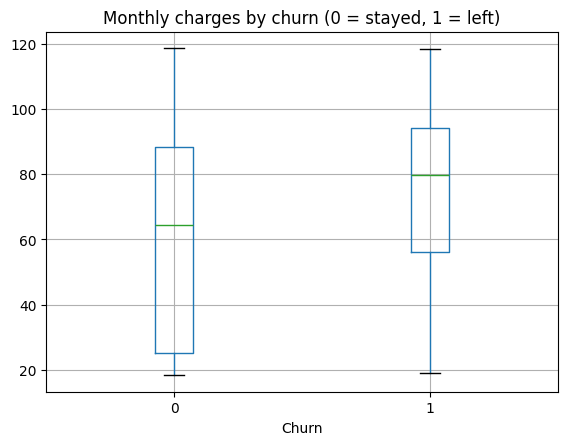

In [22]:
df.boxplot(column="MonthlyCharges", by="Churn")
plt.title("Monthly charges by churn (0 = stayed, 1 = left)")
plt.suptitle("")
plt.show()

Monthly charges by churn:
- Customers who stayed: median bill of about $64.

- Customers who left: median bill of about $80

Leavers pay more per month on average, and their bills sit higher across the middle half of the range. The two groups overlap a lot, so the bill is a useful signal but not the whole story. Customers with high bills may be worth an early check-in or a review of their plan.

#Split the data 80/20 with stratify=y

I need to split the data into a training set (80%), used to fit the model, and a test set (20%), held back to measure how well it works on customers it hasn't seen. A plain random split could leave the test set with a different churn rate than the training set.


In [23]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Churn rate train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Churn rate train: 0.266 | test: 0.266


It tells the split to keep the class proportions the same in both sets. Churners are about 26.5% of the data, so both the training set and the test set should contain about 26.5% churners. The split is still random, but it's done separately within each class so the ratio is preserved.

Why the churn rate must stay the same:
* The model learns the base rate from the training set. If the test set had a much higher or lower churn rate, the evaluation would be unfair, because the model would be judged on a different mix of customers than it learned from.
* Recall depends on how many churners are in the test set. If the test set happened to have very few churners, the recall score would be based on very little data and would swing a lot.
* Because only about a quarter of customers churn, a random split could easily produce an unbalanced test set. Stratifying prevents that.

#Preprocessing Pipeline

Models only work with numbers. Some columns are numbers on very different scales, such as tenure (0–72 months) and MonthlyCharges (about $18–$119). Others are text, such as Contract and PaymentMethod.


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Numeric:", num_cols)
print("Categorical:", cat_cols)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


What I did:
* StandardScaler: rescales each numeric column to a mean of 0 and a standard deviation of 1. This stops large-range columns from dominating the model.
* OneHotEncoder: turns each text category into its own 0/1 column. For example, Contract becomes one column for month-to-month, one for one-year, and one for two-year. handle_unknown="ignore" stops the app from crashing if it sees a category the model didn't train on.
* ColumnTransformer: applies each step to the right columns in one object.

Why it's in a Pipeline:
The Pipeline learns the scaling and encoding from the training data only, then applies the same steps to the test data and to app inputs. This prevents data leakage, where information from the test set leaks into training.

#Comparing Models

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(class_weight="balanced", random_state=42),
}

for name, clf in models.items():
    pipe = Pipeline([("prep", preprocessor), ("clf", clf)])
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="recall")
    print(f"{name}: recall {scores.mean():.3f} (+/- {scores.std():.3f})")

Logistic Regression: recall 0.805 (+/- 0.036)
Decision Tree: recall 0.494 (+/- 0.013)
Random Forest: recall 0.470 (+/- 0.029)


I trained three models, each with class_weight="balanced": Logistic Regression, Decision Tree, and Random Forest.

**Why class_weight="balanced":**

About 26.5% of customers churn, so a model could score well by predicting "stay" for everyone. The balanced setting makes errors on churners count more, which pushes the model to find more of them.

**How I compared them:**

I used 5-fold cross-validation on the training data with recall as the score. Cross-validation splits the training data five ways, trains on four parts and tests on the fifth, then repeats. The test set stays untouched until the final evaluation.

**Results (mean recall across folds):**

*   Logistic Regression: recall 0.805 (+/- 0.036)
*   Decision Tree: recall 0.494 (+/- 0.013)
*   Random Forest: recall 0.470 (+/- 0.029)

The gap is large. Logistic Regression catches about 80% of churners in the training folds, while the tree-based models catch about half. Logistic Regression is a simpler model. With balanced class weights, it's more willing to predict churn, which is what raises recall.

Logistic Regression had the highest recall, so I can use it for tuning in Next Step.



#Tune with GridSearchCV on the best model

In [26]:
from sklearn.model_selection import GridSearchCV

# Create a pipeline with the preprocessor and Logistic Regression
pipe_lr = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42))
])

# Define a parameter grid to tune regularization strength 'C'
param_grid_lr = {
    "clf__C": [0.01, 0.1, 1, 10]
}

# Run Grid Search for Logistic Regression
grid_lr = GridSearchCV(pipe_lr, param_grid_lr, scoring="recall", cv=5, n_jobs=-1)
grid_lr.fit(X_train, y_train)

print("Logistic Regression best CV recall:", round(grid_lr.best_score_, 3))

Logistic Regression best CV recall: 0.805


I tuned the Logistic Regression model.

The gap is large. Logistic Regression catches about 80% of churners in the training folds. Untuned Random Forest catches about 47%. Random Forest with default settings grows very deep trees, which fit the training folds closely and miss churners in the held-out folds. The gap shrinks once Random Forest is tuned.

In [28]:
print(grid_lr.best_params_)

{'clf__C': 1}


#Confusion Matrix and Classification Report

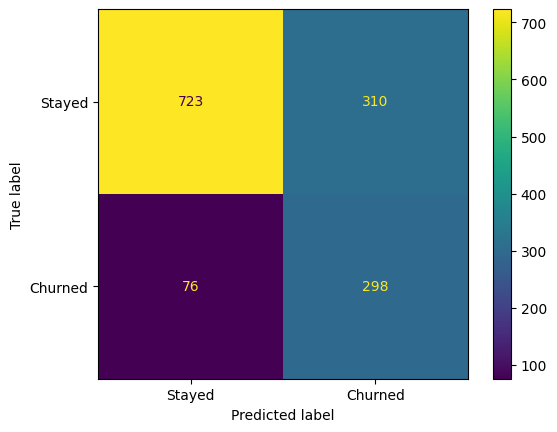

              precision    recall  f1-score   support

      Stayed       0.90      0.70      0.79      1033
     Churned       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



In [27]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

y_pred = grid_lr.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Stayed", "Churned"]
)
plt.show()

print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))

I evaluated the final Logistic Regression model on the 1,407 test customers, none of whom were used in training or tuning.

#Evaluation on the test set

I evaluated the final Logistic Regression model on the 1,407 test customers, none of whom were used in training or tuning. The test set has 374 churners.

Confusion matrix:
- 723 stayed customers correctly predicted to stay
- 310 stayed customers wrongly predicted to churn (false alarms)
- 76 churners missed (predicted to stay)
- 298 churners correctly caught

The model catches 80% of customers who leave, which matches the 0.805 from cross-validation.

Precision for churners: 0.49. About half of the customers flagged as likely to leave actually do.

The trade-off: because the model prioritizes recall, it produces 310 false alarms. For this business, that cost is acceptable because a retention offer to a loyal customer costs far less than losing a churner. The 76 missed churners show the model still has a blind spot.

#Recommneded Buisness Idea

1. Move month-to-month customers to longer contracts.
   Month-to-month customers churn at about 43%, compared with about 3% on two-year contracts. Offer a discount for switching to a one-year plan, and target month-to-month customers first.

2. Encourage automatic payment.
   Electronic check users churn at about 45%, compared with about 15–19% for the other payment methods. Offer a small discount for switching to automatic payment. This is the lowest-cost action in this list.

3. Focus retention on the first year.
   Customers in their first 12 months churn at about 48%, compared with about 9% after four years. Schedule an onboarding check-in in the first few months, and review the customers the model flags as High risk during this period.

4. Review fiber optic service and tech support.
   Fiber optic customers churn at about 42%, compared with about 19% on DSL. Customers without tech support churn at about 42%, compared with about 15% for those who have it. Offer a free tech support trial to fiber customers, and check whether fiber pricing or reliability is driving the gap.
  

In [30]:
import joblib
joblib.dump(grid_lr.best_estimator_, "churn_model.joblib")

['churn_model.joblib']